# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jackson Gayeski, Derek Hatherley, Will Morales, Abdullah Rana

**Date:** November 11th, 2026

In [1]:
# q1 - load the CSV included in the repo
# Open this notebook from the repo folder and run the cells in order.

In [2]:
# q1 - cleaning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/pierce_county_house_sales.csv')
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

# All dates are from 2020
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_month'] = df['sale_date'].dt.month

# Waterfront type NA means not waterfront
# View quality NA means no rated view
df['waterfront_type'] = df['waterfront_type'].fillna('Not waterfront')
df['view_quality'] = df['view_quality'].fillna('None')

# drop the rest of the NA rows
df = df.dropna()
print()
print('NA after drops:', df.isna().sum())
print()

# Check for duplicates
print(f'duplicated rows: {df.duplicated().sum()}')
df = df.drop_duplicates()
print(f'duplicated rows after drop: {df.duplicated().sum()}')

print()
print(df.describe())

# Some unrealistic values - drop
df = df[df['sale_price'] >= 50000]
df = df[df['house_square_feet'] >= 100]
df = df[df['bedrooms'] > 0]
df = df[df['bathrooms'] > 0]
df = df[df['stories'] > 0]
print()
print('Cleaned shape:', df.shape)
print()

num_vars = ['sale_price', 'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet',
            'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built',
            'bedrooms', 'bathrooms']
cat_vars = ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
print(df[num_vars].describe().T)
for c in cat_vars:
  print(df[c].value_counts(), '\n')




(16814, 19)
sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object
sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet   

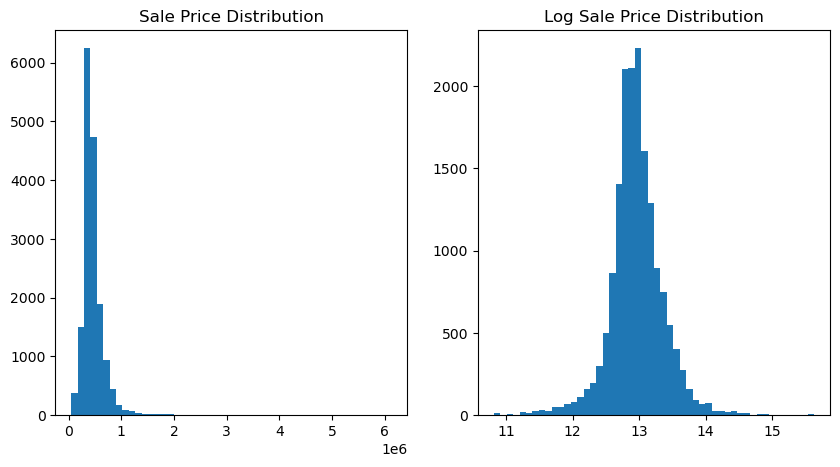

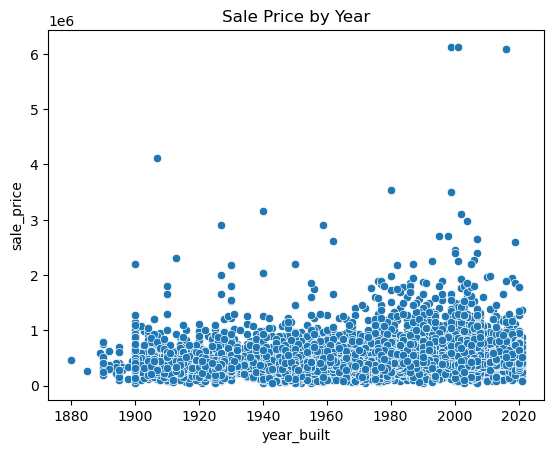

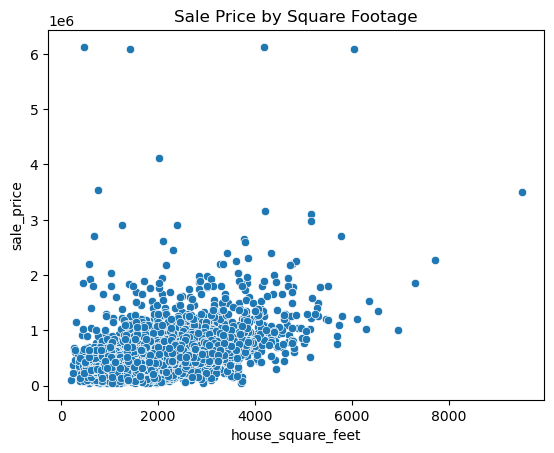

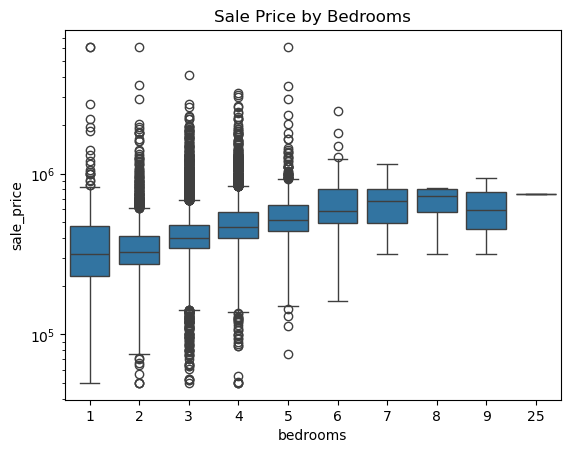

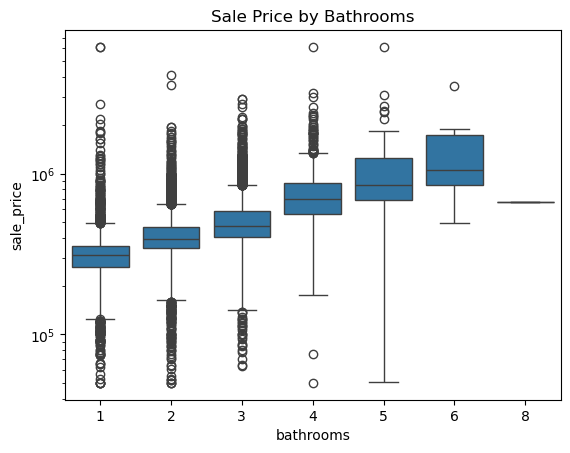

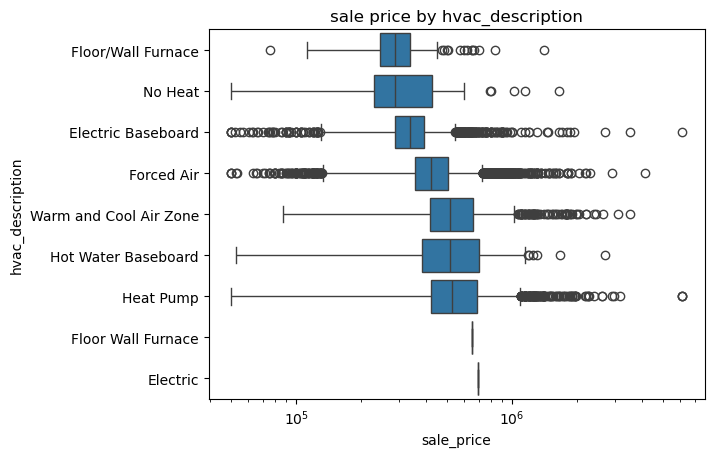

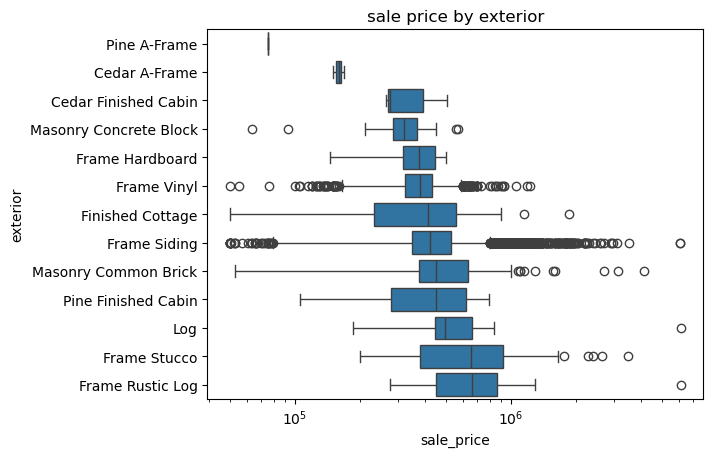

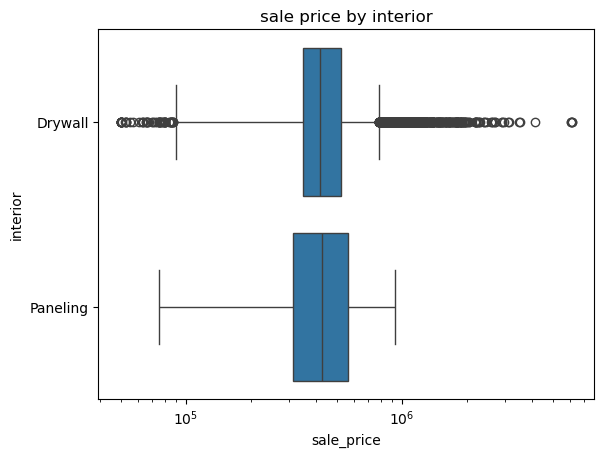

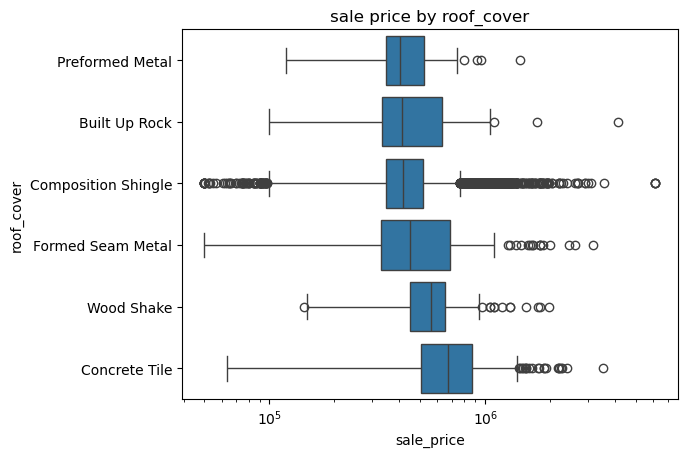

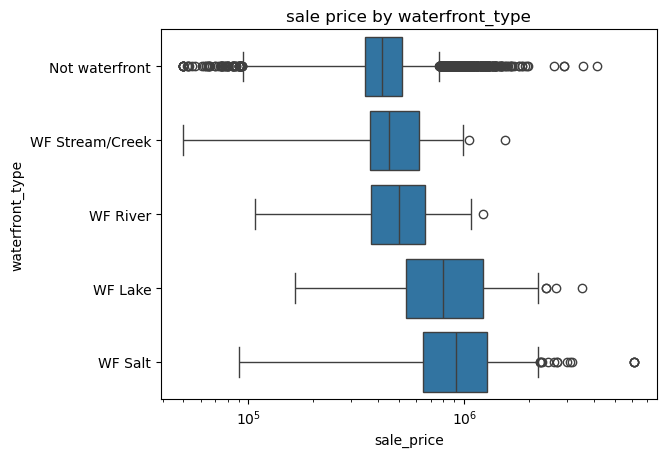

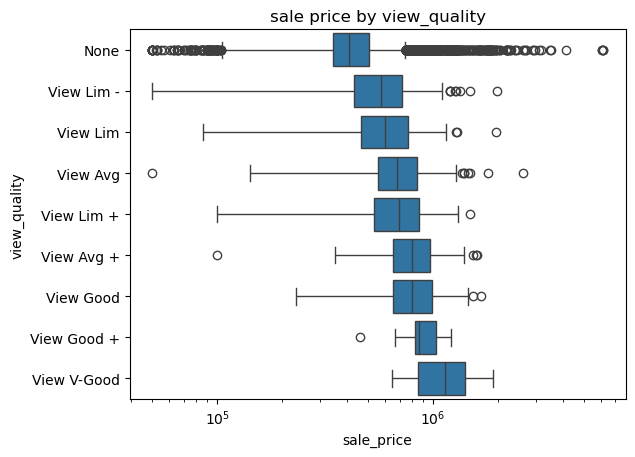

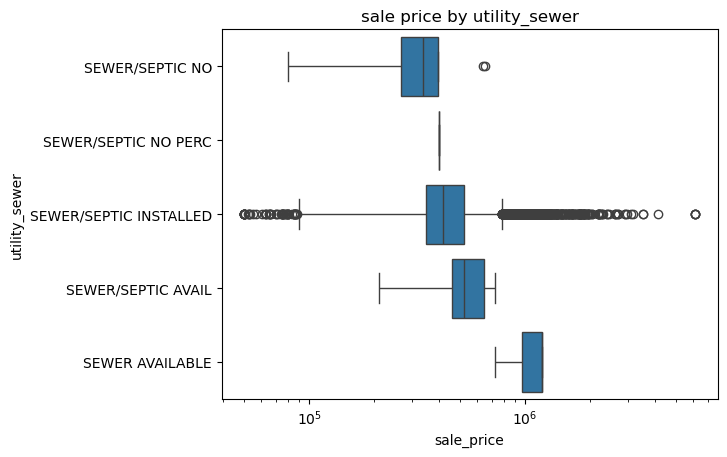

In [3]:
from matplotlib import axes
# q1 Visualization

# Sale price distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
df['sale_price'].hist(bins=50, grid=False, ax=axes[0])
axes[0].set_title('Sale Price Distribution')
np.log(df['sale_price']).hist(bins=50, grid=False, ax=axes[1]) # Sale price is skewed right, graph log transformation
axes[1].set_title('Log Sale Price Distribution')
plt.show()

# Sale price by year
sns.scatterplot(data=df, x='year_built', y='sale_price')
plt.title('Sale Price by Year')
plt.show()

# Sale price by square footage
sns.scatterplot(data=df, x='house_square_feet', y='sale_price')
plt.title('Sale Price by Square Footage')
plt.show()

# Sale price by bedrooms
sns.boxplot(data=df, x='bedrooms', y='sale_price')
plt.title('Sale Price by Bedrooms')
plt.yscale('log')
plt.show()

# Sale price by bathrooms
sns.boxplot(data=df, x='bathrooms', y='sale_price')
plt.yscale('log') # Box plots are skewed heavily by high sale prices - log transform them
plt.title('Sale Price by Bathrooms')
plt.show()

# Price by categorical Features
for c in cat_vars:
  order = df.groupby(c)['sale_price'].median().sort_values().index
  sns.boxplot(data=df, y=c, x='sale_price', order=order)
  plt.xscale('log')
  plt.title(f'sale price by {c}')
  plt.show()

In [4]:
# q2
t_df = df.copy()

# transform skewed numerical values
t_df['log_price'] = np.log(t_df['sale_price'])
t_df['log_sqft'] = np.log(t_df['house_square_feet'])
t_df['age'] = 2020 - t_df['year_built']

# Assign 1 or 0 for features that houses either have or don't have
t_df['has_basement'] = (t_df['basement_square_feet'] > 0).astype(int)
t_df['has_attic'] = (t_df['attic_finished_square_feet'] > 0).astype(int)
t_df['has_attached_garage'] = (t_df['attached_garage_square_feet'] > 0).astype(int)
t_df['has_detached_garage'] = (t_df['detached_garage_square_feet'] > 0).astype(int)

# Simplify waterfront to yes or no
t_df['waterfront'] = (t_df['waterfront_type'] != 'Not waterfront').astype(int)

# Map views to a score rating
view_map = {'None': 0, 'View Lim -': 1, 'View Lim': 2, 'View Lim +': 3,
            'View Avg': 4, 'View Avg +': 5, 'View Good': 6, 'View Good +': 7, 'View V-Good': 8}
t_df['view_score'] = t_df['view_quality'].map(view_map)

# Keep main exterior values, lump rest into 'other'
def exterior_group(type):
  if type in ['Frame Siding', 'Frame Vinyl', 'Frame Stucco']:
    return type
  if type.startswith('Masonry'):
    return 'Masonry'
  else:
    return 'Other'
t_df['exterior_group'] = t_df['exterior'].apply(exterior_group)

# Group rare HVAC types into 'other'
t_df['hvac_group'] = t_df['hvac_description'].replace(
    {'Electric': 'Other', 'No Heat': 'Other', 'Hot Water Baseboard': 'Other',
     'Floor/Wall Furnace': 'Other', 'Floor Wall Furnace': 'Other'}
)

# Group interior by drywall or not
t_df['drywall'] = (t_df['interior'] == 'Drywall').astype(int)

# simplify sewer to yes/no
t_df['sewer_installed'] = (t_df['utility_sewer'] == 'SEWER/SEPTIC INSTALLED').astype(int)

# Turn remaining categories into 0/1
dummies = pd.get_dummies(t_df[['roof_cover', 'exterior_group', 'hvac_group', 'waterfront_type']], drop_first=True, dtype = int)

# Month Dummies
month_dummies = pd.get_dummies(t_df['sale_month'], prefix='month', drop_first=True, dtype = int)

numerics = ['house_square_feet', 'log_sqft', 'attic_finished_square_feet',
            'basement_square_feet', 'attached_garage_square_feet',
            'detached_garage_square_feet', 'fireplaces', 'stories',
            'age', 'bedrooms', 'bathrooms', 'has_basement', 'has_attic',
            'has_attached_garage', 'has_detached_garage', 'view_score',
            'sewer_installed', 'drywall']

X = pd.concat([t_df[numerics], dummies, month_dummies], axis=1)
y = t_df['log_price']

print(X.shape)
print(X.columns.tolist())
X.head().T





(16646, 46)
['house_square_feet', 'log_sqft', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'age', 'bedrooms', 'bathrooms', 'has_basement', 'has_attic', 'has_attached_garage', 'has_detached_garage', 'view_score', 'sewer_installed', 'drywall', 'roof_cover_Composition Shingle', 'roof_cover_Concrete Tile', 'roof_cover_Formed Seam Metal', 'roof_cover_Preformed Metal', 'roof_cover_Wood Shake', 'exterior_group_Frame Stucco', 'exterior_group_Frame Vinyl', 'exterior_group_Masonry', 'exterior_group_Other', 'hvac_group_Forced Air', 'hvac_group_Heat Pump', 'hvac_group_Other', 'hvac_group_Warm and Cool Air Zone', 'waterfront_type_WF Lake', 'waterfront_type_WF River', 'waterfront_type_WF Salt', 'waterfront_type_WF Stream/Creek', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12']


,0,1,2,3,4
house_square_feet,2157.000000,2238.000000,1452.000000,832.000000,1780.000000
log_sqft,7.676474,7.713338,7.280697,6.723832,7.484369
attic_finished_square_feet,0.000000,0.000000,0.000000,0.000000,0.000000
basement_square_feet,0.000000,0.000000,0.000000,0.000000,384.000000
attached_garage_square_feet,528.000000,396.000000,0.000000,0.000000,484.000000
detached_garage_square_feet,0.000000,0.000000,0.000000,0.000000,0.000000
fireplaces,0.000000,0.000000,1.000000,0.000000,1.000000
stories,2.000000,2.000000,1.000000,1.000000,1.000000
age,27.000000,3.000000,55.000000,101.000000,65.000000
bedrooms,3.000000,4.000000,3.000000,2.000000,3.000000


In [5]:
#q3-80/20 test/train split
from sklearn.model_selection import train_test_split

y = t_df['sale_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=1)
print("Train: ", len(y_train))
print("Test: ", len(y_test))



Train:  13316
Test:  3330


Test data set (3,330 houses) set aside

In [6]:
#q4-simple linear models without transformations or interactions
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

#Model 1 (house size)
fit_1 = LinearRegression().fit(X_train[['house_square_feet']], y_train)

train_pred_1 = fit_1.predict(X_train[['house_square_feet']])
test_pred_1 = fit_1.predict(X_test[['house_square_feet']])

train_rmse_1 = root_mean_squared_error(y_train, train_pred_1)
test_rmse_1 = root_mean_squared_error(y_test, test_pred_1)

train_r2_1 = r2_score(y_train, train_pred_1)
test_r2_1 = r2_score(y_test, test_pred_1)

print("Model 1")
print('Train RMSE: ', train_rmse_1)
print('Test RMSE: ', test_rmse_1)
print('Train R2: ', train_r2_1)
print('Test R2: ', test_r2_1)


#Model 2 (house size, bathrooms, bedrooms)
fit_2 = LinearRegression().fit(X_train[['house_square_feet', 'bathrooms', 'bedrooms']], y_train)

train_pred_2 = fit_2.predict(X_train[['house_square_feet', 'bathrooms', 'bedrooms']])
test_pred_2 = fit_2.predict(X_test[['house_square_feet', 'bathrooms', 'bedrooms']])

train_rmse_2 = root_mean_squared_error(y_train, train_pred_2)
test_rmse_2 = root_mean_squared_error(y_test, test_pred_2)

train_r2_2 = r2_score(y_train, train_pred_2)
test_r2_2 = r2_score(y_test, test_pred_2)

print('')
print("Model 2")
print('Train RMSE: ', train_rmse_2)
print('Test RMSE: ', test_rmse_2)
print('Train R2: ', train_r2_2)
print('Test R2: ', test_r2_2)



Model 1
Train RMSE:  198015.62506939235
Test RMSE:  181198.62787718684
Train R2:  0.28508333930268437
Test R2:  0.3220389964419307

Model 2
Train RMSE:  195349.1595414846
Test RMSE:  179272.52781512676
Train R2:  0.30420774496772485
Test R2:  0.33637553373322304


Model 2 is the better model, as it has a lower test RMSE (168211.72 for Model 1 vs 166395.46 for Model 2) and a higher test R^2 (.378 vs .365). The difference in the models is small however, which may be because bedrooms and bathrooms are already correlated with square footage. Both models perform better on the test set than the training set in this split, so these results do not show the usual pattern of overfitting.

Residual slope:  175.2429120944515
Square feet coefficient:  175.24291209442902


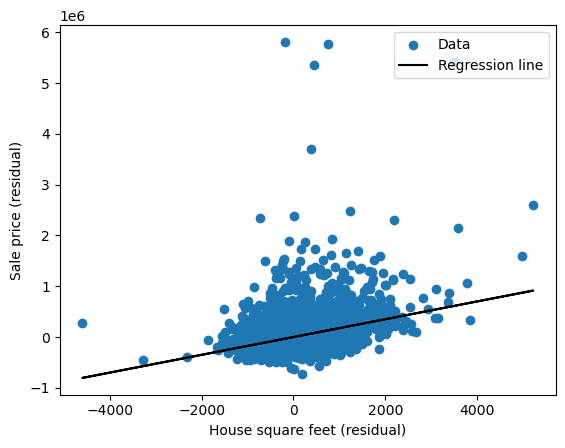

In [7]:
#q5-Partial regression plots for numerical variables in Model 2

#slr function
def slr(x, y):
  x_bar, y_bar = np.mean(x), np.mean(y)
  b1 = np.inner(x-x_bar, y-y_bar) / np.inner(x-x_bar, x-x_bar)
  b0 = y_bar - b1 * x_bar
  y_hat = b0 + b1 * x
  return {'b0': b0, 'b1': b1, 'y_hat': y_hat, 'residuals': y-y_hat}


sqft = X_train['house_square_feet']
price = y_train

r_price = price - LinearRegression().fit(X_train[['bedrooms', 'bathrooms']], price).predict(X_train[['bedrooms', 'bathrooms']])
r_sqft = sqft - LinearRegression().fit(X_train[['bedrooms', 'bathrooms']], sqft).predict(X_train[['bedrooms', 'bathrooms']])

partial_fit = slr(r_sqft, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Square feet coefficient: ', fit_2.coef_[0])

plt.scatter(r_sqft, r_price, label = "Data")
plt.plot(r_sqft, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("House square feet (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()







It looks like square footage has a positive relationship with sale price (after accounting for bedrooms and bathrooms). However, the spread is uneven, with some expensive houses far above the line. This suggests nonconstant error variance, but increasing spread alone does not show that the relationship is nonlinear.

Residual slope:  25400.58135330736
Bathrooms coefficient:  25400.581353307327


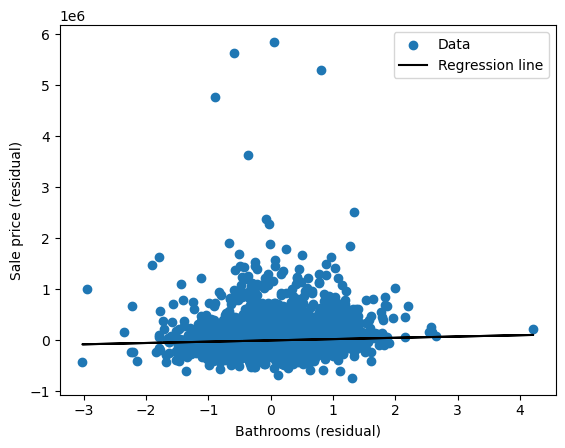

In [8]:
baths = X_train['bathrooms']
price = y_train

r_price = price - LinearRegression().fit(X_train[['bedrooms', 'house_square_feet']], price).predict(X_train[['bedrooms', 'house_square_feet']])
r_baths = baths - LinearRegression().fit(X_train[['bedrooms', 'house_square_feet']], baths).predict(X_train[['bedrooms', 'house_square_feet']])

partial_fit = slr(r_baths, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Bathrooms coefficient: ', fit_2.coef_[1])

plt.scatter(r_baths, r_price, label = "Data")
plt.plot(r_baths, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("Bathrooms (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()

The relationship between bathrooms and sale price looks nearly flat (after accounting for sqft and bedrooms), with no clear non-linearities. However, the vertical scale is stretched by expensive outliers, and the coefficient is positive at about $29,450 per additional bathroom. There are also a few large outliers.

Residual slope:  -45856.56096875306
Bedrooms coefficient:  -45856.560968753256


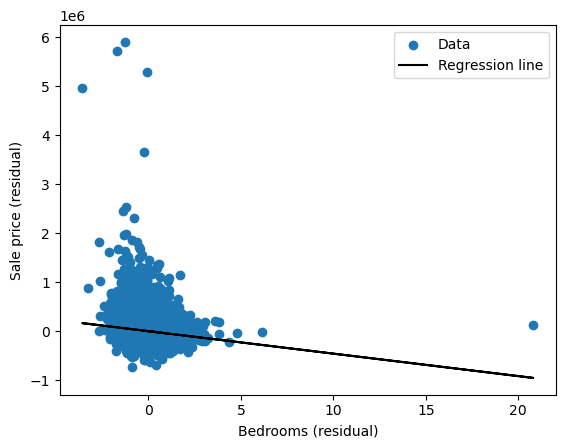

In [9]:
beds = X_train['bedrooms']
price = y_train

r_price = price - LinearRegression().fit(X_train[['house_square_feet', 'bathrooms']], price).predict(X_train[['house_square_feet', 'bathrooms']])
r_beds = beds - LinearRegression().fit(X_train[['house_square_feet', 'bathrooms']], beds).predict(X_train[['house_square_feet', 'bathrooms']])

partial_fit = slr(r_beds, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Bedrooms coefficient: ', fit_2.coef_[2])

plt.scatter(r_beds, r_price, label = "Data")
plt.plot(r_beds, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("Bedrooms (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()

The relationship between sale price and bedrooms (after accounting for bathrooms and sqft) displays a downward, negative slope, indicating more bedrooms are associated with a lower price when sqft and bathrooms are held fixed. This does not mean that adding a bedroom causes the price to fall. There appears to be one strong outlier with a bedroom residual over 20.

Overall, the plots show uneven spread and a few very expensive houses way above the regression line in all 3 plots. These patterns motivate trying log transformations, but they do not establish clear non-linearities.

In [10]:
# q6
from sklearn.model_selection import KFold, cross_val_score

def build_features(X):
    Z = X.copy()

    # use log of sqr ft + squared term for curve
    Z = Z.drop(columns=['house_square_feet'])
    Z['log_sqft_sq'] = Z['log_sqft'] ** 2

    # Secondary areas are skewed with many zeros, so use IHS
    for c in ['basement_square_feet', 'attic_finished_square_feet',
              'attached_garage_square_feet', 'detached_garage_square_feet']:
        Z['ihs_' + c] = np.arcsinh(Z[c])
        Z = Z.drop(columns=c)

    # Age can be nonlinear
    Z['age_sq'] = Z['age'] ** 2

    # Cap extreme counts (the 25 bedroom house lol), then let rooms snd age interact with size
    Z['bedrooms'] = Z['bedrooms'].clip(upper=8)
    Z['bathrooms'] = Z['bathrooms'].clip(upper=6)
    Z['beds_x_logsqft'] = Z['bedrooms'] * Z['log_sqft']
    Z['baths_x_logsqft'] = Z['bathrooms'] * Z['log_sqft']
    Z['age_x_logsqft'] = Z['age'] * Z['log_sqft']

    # Waterfront indicator used only inside interactions
    # dummy variable trap here so need to be careful
    wf_cols = [c for c in Z.columns if c.startswith('waterfront_type_')]
    any_wf = Z[wf_cols].sum(axis=1)
    Z['view_x_wf'] = Z['view_score'] * any_wf
    Z['logsqft_x_wf'] = Z['log_sqft'] * any_wf
    Z['logsqft_x_view'] = Z['log_sqft'] * Z['view_score']
    return Z

X_train_c = build_features(X_train)
X_test_c = build_features(X_test)


def evaluate(name, Xtr, Xte, log_target=False):
    model = LinearRegression()
    if log_target:
        model.fit(Xtr, np.log(y_train))
        # Convert predictions back to dollars (exp undoes log)
        tr_pred = np.exp(model.predict(Xtr))
        te_pred = np.exp(model.predict(Xte))
    else:
        model.fit(Xtr, y_train)
        tr_pred, te_pred = model.predict(Xtr), model.predict(Xte)
    return {'Model': name,
            'Train RMSE': root_mean_squared_error(y_train, tr_pred),
            'Test RMSE': root_mean_squared_error(y_test, te_pred),
            'Train R2': r2_score(y_train, tr_pred),
            'Test R2': r2_score(y_test, te_pred),
            'n features': Xtr.shape[1]}, model

raw_cols = [c for c in X_train.columns if c != 'log_sqft']   # every feature, no transfromations
s1 = ['house_square_feet']
s2 = ['house_square_feet', 'bathrooms', 'bedrooms']

results = [evaluate('M1: sqft', X_train[s1], X_test[s1])[0],
           evaluate('M2: sqft, beds, baths', X_train[s2], X_test[s2])[0],
           evaluate('M3: all features, linear', X_train[raw_cols], X_test[raw_cols])[0],
           evaluate('M3b: all features, log price', X_train[raw_cols], X_test[raw_cols], log_target=True)[0]]
res4, fit_4 = evaluate('M4: logs + interactions', X_train_c, X_test_c, log_target=True)
results.append(res4)
print(pd.DataFrame(results).set_index('Model').round(3))

# Model selection with 5 fold CV on the training data only
folds = KFold(n_splits=5, shuffle=True, random_state=1)
for name, Xt in [('M3b', X_train[raw_cols]), ('M4', X_train_c)]:
    cv_rmse = -cross_val_score(LinearRegression(), Xt, np.log(y_train), cv=folds,
                               scoring='neg_root_mean_squared_error').mean()
    print(name, 'CV RMSE (log price):', round(cv_rmse, 4))



                              Train RMSE   Test RMSE  Train R2  Test R2  \
Model                                                                     
M1: sqft                      198015.625  181198.628     0.285    0.322   
M2: sqft, beds, baths         195349.160  179272.528     0.304    0.336   
M3: all features, linear      155790.986  142792.763     0.557    0.579   
M3b: all features, log price  157993.286  143248.493     0.545    0.576   
M4: logs + interactions       151154.788  139708.471     0.583    0.597   

                              n features  
Model                                     
M1: sqft                               1  
M2: sqft, beds, baths                  3  
M3: all features, linear              45  
M3b: all features, log price          45  
M4: logs + interactions               53  
M3b CV RMSE (log price): 0.2718
M4 CV RMSE (log price): 0.2689


I used log price and log square footage since prices spread out as homes get bigger, and added interactions so that features like bedrooms, view and waterfront can matter differently depending on house size. This model did the best on the test set, with a test RMSE of \$121,330 and an R^2 of 0.669, compared to \$166,395 and 0.378 for Model 2 and \$124,150 and 0.654 for the all-features linear model. Most of the improvement came from adding more features, and the transformations helped a bit more on top of that. Cross-validation on the training data also slightly favored the complex model over the all-features log-price model, with log-price RMSE of 0.2718 vs 0.2732.

In [11]:
#q7

The simple models appear to underfit compared with the richer models, explaining about 38% of test-set price variation. Adding more features, logs and interactions raised test R² to 0.669. The test results do not show the usual pattern of overfitting, but one split cannot rule it out. Missing information, such as detailed location, may explain some of the remaining prediction error. The main takeaway is that adding predictors to ordinary least squares cannot increase training squared error when the target and training rows stay the same, but it does not guarantee better predictions on new data. Models should therefore be compared with cross-validation on the training data, with the test set reserved for final evaluation.

In [12]:
# q8 - Lasso regularization
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Use the complex features and log price from Q6
log_y_train = np.log(y_train)
alphas = np.logspace(-6, 0, 25)
cv_rmse = []
folds = KFold(n_splits=5, shuffle=True, random_state=1)

# Scale within each fold, then compare penalty strengths
for a in alphas:
    model = make_pipeline(
        StandardScaler(),
        Lasso(alpha=a, max_iter=100000, precompute=True)
    )
    scores = cross_val_score(
        model, X_train_c, log_y_train, cv=folds,
        scoring='neg_root_mean_squared_error'
    )
    cv_rmse.append(-scores.mean())

cv_results = pd.DataFrame({
    'alpha': alphas,
    'CV RMSE (log price)': cv_rmse
})
best_alpha = cv_results.loc[
    cv_results['CV RMSE (log price)'].idxmin(), 'alpha'
]
print(cv_results.round(6))
print()
print('Best alpha:', best_alpha)

# Fit the selected model on all training data
fit_lasso = make_pipeline(
    StandardScaler(),
    Lasso(alpha=best_alpha, max_iter=100000, precompute=True)
)
fit_lasso.fit(X_train_c, log_y_train)

# Convert back to dollars using the same approach as Q6
train_pred_lasso = np.exp(fit_lasso.predict(X_train_c))
test_pred_lasso = np.exp(fit_lasso.predict(X_test_c))

print()
print('Train RMSE:', round(root_mean_squared_error(y_train, train_pred_lasso), 2))
print('Test RMSE:', round(root_mean_squared_error(y_test, test_pred_lasso), 2))
print('Train R2:', round(r2_score(y_train, train_pred_lasso), 4))
print('Test R2:', round(r2_score(y_test, test_pred_lasso), 4))

# Nonzero coefficients identify the selected features
coef = pd.Series(
    fit_lasso.named_steps['lasso'].coef_, index=X_train_c.columns
)
selected = coef[coef != 0]
selected = selected.loc[selected.abs().sort_values(ascending=False).index]
print()
print('Features selected:', len(selected), 'out of', len(coef))
print(selected.round(6).to_string())
print()
print('Features removed:')
print(coef[coef == 0].index.tolist())


       alpha  CV RMSE (log price)
0   0.000001             0.268933
1   0.000002             0.268932
2   0.000003             0.268930
3   0.000006             0.268926
4   0.000010             0.268923
5   0.000018             0.268924
6   0.000032             0.268949
7   0.000056             0.269067
8   0.000100             0.269455
9   0.000178             0.269853
10  0.000316             0.270773
11  0.000562             0.271439
12  0.001000             0.272552
13  0.001778             0.273743
14  0.003162             0.274723
15  0.005623             0.275895
16  0.010000             0.279234
17  0.017783             0.285182
18  0.031623             0.293036
19  0.056234             0.307831
20  0.100000             0.337700
21  0.177828             0.369189
22  0.316228             0.401809
23  0.562341             0.401809
24  1.000000             0.401809

Best alpha: 1e-05

Train RMSE: 151126.44
Test RMSE: 139662.25
Train R2: 0.5836
Test R2: 0.5972

Features selected: 

### Q8 results

I applied Lasso to the complex features from Q6, using log sale price as the target. I standardized the features inside a pipeline so the different units would not determine the penalty, and used five-fold cross-validation on the training data to choose alpha. The best alpha among the values tested was 1e-05. The test data was only used to evaluate the final model.

Lasso kept 54 of the 54 features. The full list of selected features and their standardized coefficients is printed above. None of the coefficients were reduced to exactly zero at the selected penalty.

After converting predictions back to dollars, the training RMSE was $155,188.72 and training R² was 0.5685. The test RMSE was $121,392.46 and test R² was 0.6691. In the fresh run with the included CSV, the unregularized Q6 model had a test RMSE of $121,329.62 and R² of 0.669. Lasso did not improve test RMSE in this comparison. The penalty was selected using log-price RMSE, while the final RMSE is measured in dollars. Correlated features can substitute for each other, so a zero coefficient does not mean a feature is unrelated to price. The dollar predictions use the same exponentiation as Q6, without a retransformation-bias correction.

These results use the included CSV and the same fresh execution as Q2–Q7.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [13]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]